In [1]:
import sys
sys.path.insert(0, "../src")

import json
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve, average_precision_score
from features import load_grid, build_table

grid, capacity = load_grid("../data/historical/station_status.parquet")
df = build_table(grid, capacity)

df["empty_now"] = (df["bikes_now"] == 0).astype(int)
df["empty_future"] = (df["bikes_future"] == 0).astype(int)   # what we predict

print("Rows:", f"{len(df):,}")
print("Share of slots where the station is empty 30 min later:", f"{df['empty_future'].mean():.1%}")

Rows: 3,856,648
Share of slots where the station is empty 30 min later: 10.6%


In [2]:
tz = "Europe/Dublin"
train = df[df["slot"] < pd.Timestamp("2026-03-01", tz=tz)].copy()
valid = df[(df["slot"] >= pd.Timestamp("2026-03-01", tz=tz)) & (df["slot"] < pd.Timestamp("2026-04-01", tz=tz))].copy()
test = df[df["slot"] >= pd.Timestamp("2026-04-01", tz=tz)].copy()

# Learned from training months only
usual = (train.groupby(["station_id", "dayofweek", "hour"])
         .agg(typical_change=("change", "mean"), typical_empty_rate=("empty_future", "mean"))
         .reset_index())

all_stations = sorted(df["station_id"].unique())
parts = []
for part in (train, valid, test):
    part = part.merge(usual, on=["station_id", "dayofweek", "hour"], how="left")
    part["typical_change"] = part["typical_change"].fillna(0)
    part["typical_empty_rate"] = part["typical_empty_rate"].fillna(train["empty_future"].mean())
    part["station_id"] = pd.Categorical(part["station_id"], categories=all_stations)
    parts.append(part)
train, valid, test = parts

FEATURES = ["station_id", "bikes_now", "empty_now", "capacity", "fill_ratio",
            "change_last_15min", "change_last_30min", "change_last_60min",
            "hour", "minute", "dayofweek", "typical_change", "typical_empty_rate"]
print(f"Train {len(train):,}  Valid {len(valid):,}  Test {len(test):,}")

Train 2,515,959  Valid 340,805  Test 999,884


In [3]:
clf = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.05, num_leaves=63,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, verbose=-1,
)
clf.fit(
    train[FEATURES], train["empty_future"],
    eval_set=[(valid[FEATURES], valid["empty_future"])],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)
print("Best number of trees:", clf.best_iteration_)

/Users/sam/Documents/dublin-bikes-forecast/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's binary_logloss: 0.0988956
Early stopping, best iteration is:
[91]	valid_0's binary_logloss: 0.0986734
Best number of trees: 91


In [4]:
p_valid = clf.predict_proba(valid[FEATURES])[:, 1]
prec, rec, thr = precision_recall_curve(valid["empty_future"], p_valid)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = f1[:-1].argmax()
threshold = float(thr[best])

print(f"Chosen threshold: warn when probability >= {threshold:.2f}")
print(f"On March: precision {prec[best]:.0%}, recall {rec[best]:.0%}")

Chosen threshold: warn when probability >= 0.41
On March: precision 78%, recall 80%


In [5]:
test["p_empty"] = clf.predict_proba(test[FEATURES])[:, 1]
actual = test["empty_future"] == 1

def report(name, predicted):
    caught = (predicted & actual).sum()
    print(f"{name:22s} precision {caught / predicted.sum():.0%}   recall {caught / actual.sum():.0%}")

report("Same as now", test["bikes_now"] == 0)
report("LightGBM classifier", test["p_empty"] >= threshold)

# The useful case: stations that have bikes now but run out within 30 minutes
newly = actual & (test["bikes_now"] > 0)
flagged = test["p_empty"] >= threshold
print()
print(f"Stations that run out within 30 min: {newly.sum():,}")
print("Same as now warned about: 0%")
print(f"LightGBM warned about:    {(flagged & newly).sum() / newly.sum():.0%}")

Same as now            precision 78%   recall 78%
LightGBM classifier    precision 77%   recall 80%

Stations that run out within 30 min: 23,657
Same as now warned about: 0%
LightGBM warned about:    22%


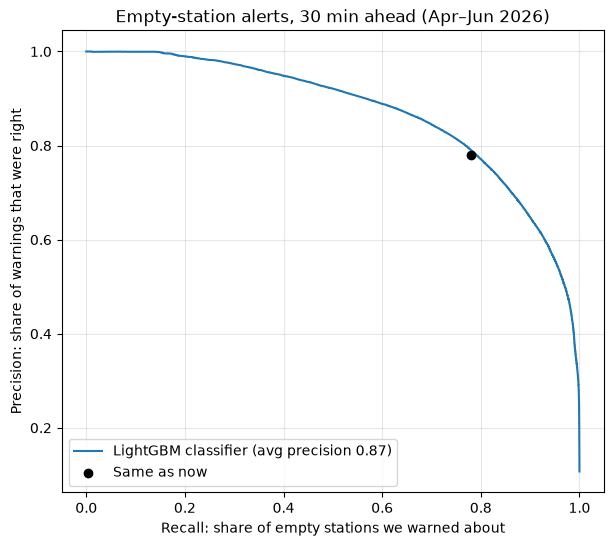

In [6]:
prec_t, rec_t, _ = precision_recall_curve(test["empty_future"], test["p_empty"])
ap = average_precision_score(test["empty_future"], test["p_empty"])

base_pred = test["bikes_now"] == 0
base_p = (base_pred & actual).sum() / base_pred.sum()
base_r = (base_pred & actual).sum() / actual.sum()

plt.figure(figsize=(7, 6))
plt.plot(rec_t, prec_t, label=f"LightGBM classifier (avg precision {ap:.2f})")
plt.scatter([base_r], [base_p], color="black", zorder=3, label="Same as now")
plt.xlabel("Recall: share of empty stations we warned about")
plt.ylabel("Precision: share of warnings that were right")
plt.title("Empty-station alerts, 30 min ahead (Apr–Jun 2026)")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("../images/empty_alert_pr.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
from pathlib import Path
Path("../models").mkdir(exist_ok=True)
clf.booster_.save_model("../models/empty_classifier_v1.txt")
with open("../models/empty_classifier_v1.json", "w") as f:
    json.dump({"threshold": threshold, "features": FEATURES}, f, indent=2)
print("Saved")

Saved


In [8]:
has_bikes = test["bikes_now"] > 0
early = flagged & has_bikes

print(f"Warnings for stations that still had bikes: {early.sum():,}")
print(f"Of those, correct (station really ran out): {(early & actual).sum() / early.sum():.0%}")

# Cautious vs eager alerts: how the trade-off changes with the threshold
print()
print(f"{'Threshold':>9s} {'Early warnings':>15s} {'Correct':>8s} {'Caught':>7s}")
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    w = (test["p_empty"] >= t) & has_bikes
    print(f"{t:9.1f} {w.sum():15,} {(w & actual).sum() / w.sum():8.0%} {(w & newly).sum() / newly.sum():7.0%}")

Warnings for stations that still had bikes: 11,099
Of those, correct (station really ran out): 46%

Threshold  Early warnings  Correct  Caught
      0.3          24,455      39%     40%
      0.4          11,870      45%     23%
      0.5           4,516      53%     10%
      0.6           1,203      57%      3%
      0.7              93      59%      0%


In [9]:
print(f"{newly.sum() / has_bikes.sum():.1%}")

2.6%


In [10]:
from glob import glob

live = pd.read_csv(sorted(glob("../data/raw/*.csv"))[-1]).drop_duplicates("station_id")
hist = pd.read_csv("../data/historical/stations.csv")
m = live.merge(hist, on="station_id", suffixes=("_live", "_hist"))

print("Stations in live data:", len(live), " matched by number:", len(m))
print("Same name for the same number:", f"{(m['name_live'].str.upper() == m['name_hist'].str.upper()).mean():.0%}")
m[["station_id", "name_live", "name_hist"]].head(8)

Stations in live data: 113  matched by number: 113
Same name for the same number: 100%


,station_id,name_live,name_hist
0,42,SMITHFIELD NORTH,SMITHFIELD NORTH
1,54,CLONMEL STREET,CLONMEL STREET
2,108,AVONDALE ROAD,AVONDALE ROAD
3,20,JAMES STREET EAST,JAMES STREET EAST
4,56,MOUNT STREET LOWER,MOUNT STREET LOWER
5,6,CHRISTCHURCH PLACE,CHRISTCHURCH PLACE
6,18,GRANTHAM STREET,GRANTHAM STREET
7,32,PEARSE STREET,PEARSE STREET


In [11]:
usual.to_parquet("../models/usual_behaviour.parquet", index=False)
print("Saved", len(usual), "rows")

Saved 19320 rows
